# Readiness Trigger  -  2026 Revision (IBTrACS)

Tests the readiness trigger threshold against historical IBTrACS data for **Regions 2, 3, 5, and 8**.

**Readiness threshold:** 1-minute sustained winds ≥ 177 kph (≈ 95.6 kt)

**Wind speed note:** The `wind_speed` column in `storms.ibtracs_tracks_geo` stores **WMO 10-minute sustained winds**. The threshold is converted before applying:

> 177 kph (1-min) × 0.88 = **155.8 kph (10-min) ≈ 84.1 kt**  -  this is what is applied to the data.

**Spatial approach:** Storm track points are connected into LineString segments between consecutive observations. Only storms where a wind-speed-qualified segment crosses the actual land boundary of the target regions are counted (landfall only  -  no buffer).

In [2]:
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import ocha_stratus as stratus
from shapely.geometry import LineString
from shapely.ops import unary_union

## Parameters

In [3]:
# Wind speed threshold
THRESHOLD_KPH_1MIN = 177  # 1-minute sustained (the stated trigger threshold)
THRESHOLD_KPH_10MIN = THRESHOLD_KPH_1MIN * 0.88  # ~155.8 kph  -  WMO 10-min equivalent
THRESHOLD_KT = THRESHOLD_KPH_10MIN / 1.852  # ~84.1 kt  -  applied to IBTrACS wind_speed column

# Buffer around target regions (km)
BUFFER_KM = 50
BUFFER_DEG = BUFFER_KM / 111

# Target regions (admin level 1 codes)
TARGET_REGIONS = ["PH02", "PH03", "PH05", "PH08"]
TARGET_REGION_NAMES = ["Region II (Cagayan Valley)", "Region III (Central Luzon)",
                        "Region V (Bicol)", "Region VIII (Eastern Visayas)"]

# Historical record
START_YEAR = 2000
END_YEAR = 2024

print(f"Threshold (1-min):  {THRESHOLD_KPH_1MIN} kph")
print(f"Threshold (10-min): {THRESHOLD_KPH_10MIN:.1f} kph = {THRESHOLD_KT:.1f} kt (applied to data)")
print(f"Buffer: {BUFFER_KM} km")
print(f"Target regions: {TARGET_REGION_NAMES}")

Threshold (1-min):  177 kph
Threshold (10-min): 155.8 kph = 84.1 kt (applied to data)
Buffer: 50 km
Target regions: ['Region II (Cagayan Valley)', 'Region III (Central Luzon)', 'Region V (Bicol)', 'Region VIII (Eastern Visayas)']


## Load Admin Boundaries

In [4]:
phl_admin_1 = stratus.codab.load_codab_from_fieldmaps(iso3="PHL", admin_level=1)
phl_admin_1.head()

,fid,adm1_id,adm1_src,adm1_name,adm1_name1,adm1_name2,adm0_id,adm0_src,adm0_name,adm0_name1,...,region2_nm,region1_cd,region1_nm,status_cd,status_nm,wld_date,wld_update,wld_view,wld_notes,geometry
0,2293,PHL-20231113-01,PH01,Region I (Ilocos Region),None,None,PHL-20250729,PHL,Philippines,Philippines,...,South-eastern Asia,142,Asia,1,State,2025-02-24,2025-07-29,intl,None,"MULTIPOLYGON (((119.86648 15.81515, 119.86631 ..."
1,2294,PHL-20231113-02,PH02,Region II (Cagayan Valley),None,None,PHL-20250729,PHL,Philippines,Philippines,...,South-eastern Asia,142,Asia,1,State,2025-02-24,2025-07-29,intl,None,"MULTIPOLYGON (((121.18967 15.9771, 121.18786 1..."
2,2295,PHL-20231113-03,PH03,Region III (Central Luzon),None,None,PHL-20250729,PHL,Philippines,Philippines,...,South-eastern Asia,142,Asia,1,State,2025-02-24,2025-07-29,intl,None,"MULTIPOLYGON (((120.08238 14.75042, 120.08231 ..."
3,2296,PHL-20231113-04,PH04,Region IV-A (Calabarzon),None,None,PHL-20250729,PHL,Philippines,Philippines,...,South-eastern Asia,142,Asia,1,State,2025-02-24,2025-07-29,intl,None,"MULTIPOLYGON (((120.82804 13.68708, 120.82791 ..."
4,2297,PHL-20231113-05,PH05,Region V (Bicol Region),None,None,PHL-20250729,PHL,Philippines,Philippines,...,South-eastern Asia,142,Asia,1,State,2025-02-24,2025-07-29,intl,None,"MULTIPOLYGON (((122.92814 13.11336, 122.92813 ..."


In [5]:
# Inspect available columns to confirm region code field
print(phl_admin_1.columns.tolist())
print(phl_admin_1[[c for c in phl_admin_1.columns if 'code' in c.lower() or 'name' in c.lower()]].head(20))

['fid', 'adm1_id', 'adm1_src', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm0_id', 'adm0_src', 'adm0_name', 'adm0_name1', 'adm0_name2', 'src_lvl', 'src_lang', 'src_lang1', 'src_lang2', 'src_date', 'src_update', 'src_name', 'src_name1', 'src_lic', 'src_url', 'src_grp', 'iso_cd', 'iso_2', 'iso_3', 'iso_3_grp', 'region3_cd', 'region3_nm', 'region2_cd', 'region2_nm', 'region1_cd', 'region1_nm', 'status_cd', 'status_nm', 'wld_date', 'wld_update', 'wld_view', 'wld_notes', 'geometry']
                                            adm1_name adm1_name1 adm1_name2  \
0                            Region I (Ilocos Region)       None       None   
1                          Region II (Cagayan Valley)       None       None   
2                          Region III (Central Luzon)       None       None   
3                            Region IV-A (Calabarzon)       None       None   
4                             Region V (Bicol Region)       None       None   
5                         Region VI (Wester

In [6]:
# Filter to target regions  -  adjust column name if needed based on output above
pcode_col = [c for c in phl_admin_1.columns if 'src' in c.lower()][0]
print(f"Using column: {pcode_col}")
print(phl_admin_1[pcode_col].unique())

target_regions_gdf = phl_admin_1[phl_admin_1[pcode_col].isin(TARGET_REGIONS)].copy()
print(f"\nMatched {len(target_regions_gdf)} regions:")
print(target_regions_gdf[[pcode_col]].to_string())

Using column: adm1_src
['PH01' 'PH02' 'PH03' 'PH04' 'PH05' 'PH06' 'PH07' 'PH08' 'PH09' 'PH10'
 'PH11' 'PH12' 'PH13' 'PH14' 'PH16' 'PH17' 'PH19']

Matched 4 regions:
  adm1_src
1     PH02
2     PH03
4     PH05
7     PH08


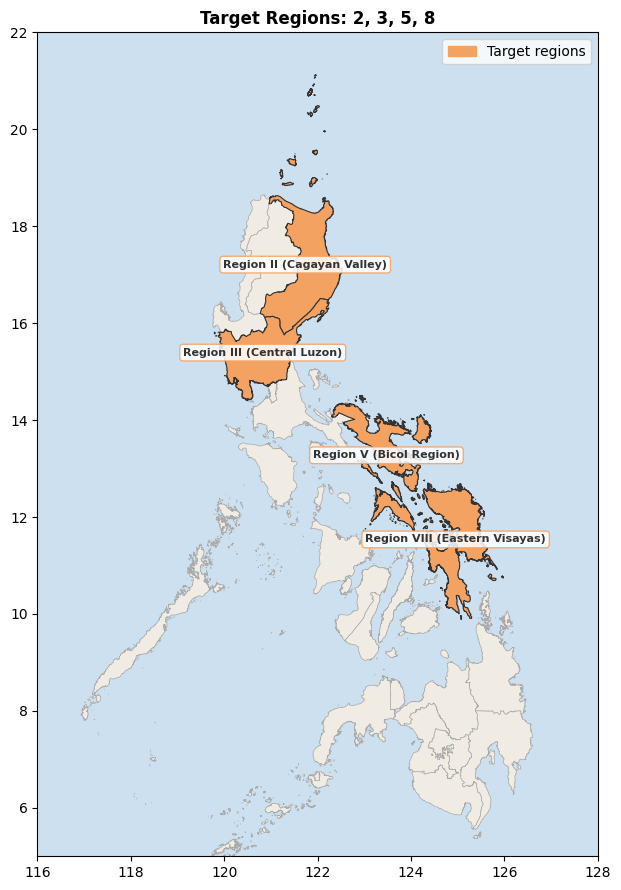

In [7]:
# Dissolve into single geometry (used for intersection checks  -  no buffer applied)
target_union = unary_union(target_regions_gdf.geometry)
target_buffered = target_union.buffer(BUFFER_DEG)  # kept for map display only

# Map with region labels
fig, ax = plt.subplots(figsize=(7, 9))
ax.set_facecolor("#cde0f0")
phl_admin_1.plot(ax=ax, color="#f0ece3", edgecolor="#aaa", linewidth=0.5)
target_regions_gdf.plot(ax=ax, color="#f4a261", edgecolor="#333", linewidth=0.8)

# Label each target region at its centroid
for _, row in target_regions_gdf.iterrows():
    centroid = row.geometry.centroid
    ax.annotate(
        row["adm1_name"], xy=(centroid.x, centroid.y),
        ha="center", va="center", fontsize=8, fontweight="bold", color="#333",
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#f4a261", alpha=0.85)
    )

ax.set_xlim(116, 128)
ax.set_ylim(5, 22)
ax.set_title("Target Regions: 2, 3, 5, 8", fontweight="bold")
ax.legend(handles=[
    mpatches.Patch(color="#f4a261", label="Target regions"),
])
plt.tight_layout()
plt.show()

## Fetch IBTrACS Data

In [8]:
def fetch_ibtracs_data(start_date, end_date):
    query = f"""
    SELECT *
    FROM storms.ibtracs_tracks_geo
    WHERE
        basin = 'WP'
        AND valid_time BETWEEN '{start_date.date()}' AND '{end_date.date()}'
    """
    return gpd.read_postgis(query, stratus.get_engine(stage="prod"), geom_col="geometry")

tracks_pts = fetch_ibtracs_data(
    pd.Timestamp(f"{START_YEAR}-01-01"),
    pd.Timestamp(f"{END_YEAR}-12-31")
)

print(f"Track points loaded: {len(tracks_pts):,}")
print(f"Date range: {tracks_pts['valid_time'].min()} → {tracks_pts['valid_time'].max()}")
print(f"Unique storms: {tracks_pts['storm_id'].nunique()}")
print(f"\nWind speed column stats:")
print(tracks_pts['wind_speed'].describe())

Track points loaded: 22,115
Date range: 2000-05-04 18:00:00 → 2024-12-25 12:00:00
Unique storms: 604

Wind speed column stats:
count    14177.000000
mean        60.478239
std         20.302206
min         35.000000
25%         45.000000
50%         55.000000
75%         75.000000
max        125.000000
Name: wind_speed, dtype: float64


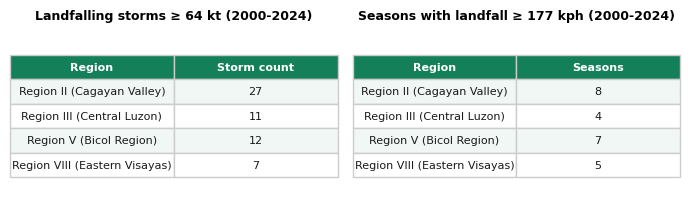

In [9]:
# Storms per region by threshold.
# For the readiness threshold (count_seasons=True): count unique seasons (years) where
# at least one qualifying storm made landfall  -  enforcing the once-per-season rule.
def count_storms_per_region(tracks_gdf, threshold_kt, store_storm_ids=False, count_seasons=False):
    counts = []
    storm_region_map = {}
    for _, region_row in target_regions_gdf.iterrows():
        region_geom = region_row.geometry
        triggered_years = set()
        storm_count = 0
        for storm_id, grp in tracks_gdf.sort_values("valid_time").groupby("storm_id"):
            year = grp["valid_time"].dt.year.iloc[0]
            for i in range(len(grp) - 1):
                p0 = grp.iloc[i]
                p1 = grp.iloc[i + 1]
                if pd.isna(p0["wind_speed"]) or pd.isna(p1["wind_speed"]):
                    continue
                if min(p0["wind_speed"], p1["wind_speed"]) < threshold_kt:
                    continue
                seg = LineString([(p0.geometry.x, p0.geometry.y), (p1.geometry.x, p1.geometry.y)])
                if seg.intersects(region_geom):
                    triggered_years.add(year)
                    storm_count += 1
                    if store_storm_ids:
                        storm_region_map.setdefault(storm_id, []).append(region_row["adm1_name"])
                    break
        value = len(triggered_years) if count_seasons else storm_count
        counts.append({"Region": region_row["adm1_name"], "Count": value})
    return pd.DataFrame(counts), storm_region_map

df_64kt, _ = count_storms_per_region(tracks_pts, 64)
df_readiness, storm_region_map = count_storms_per_region(
    tracks_pts, THRESHOLD_KT, store_storm_ids=True, count_seasons=True
)

def render_table(ax, df, title, col_label):
    display_df = df.rename(columns={"Count": col_label})
    ax.axis("off")
    ax.set_title(title, fontsize=9, fontweight="bold", pad=10)
    table = ax.table(
        cellText=display_df.values.tolist(),
        colLabels=list(display_df.columns),
        loc="center", cellLoc="center"
    )
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.5)
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if row == 0:
            cell.set_facecolor("#14805a")
            cell.set_text_props(color="white", fontweight="bold")
        else:
            cell.set_facecolor(["#f0f7f4", "#ffffff"][(row - 1) % 2])
            cell.set_text_props(color="#1a1a1a")

fig, axes = plt.subplots(1, 2, figsize=(7, 2.2))
render_table(axes[0], df_64kt,      f"Landfalling storms ≥ 64 kt ({START_YEAR}-{END_YEAR})",       "Storm count")
render_table(axes[1], df_readiness, f"Seasons with landfall ≥ {THRESHOLD_KPH_1MIN} kph ({START_YEAR}-{END_YEAR})", "Seasons")
plt.tight_layout()
plt.show()

## Build Track Segments and Test Readiness Trigger

For each storm, consecutive track points are connected into LineString segments. This ensures we catch storms that pass through a region between two observations (not just at observed points).

A landfall is detected when:
1. The **minimum wind speed** of the two endpoints ≥ threshold (both points already at or above threshold)
2. The segment **intersects** the actual land boundary of the target regions (no buffer)

In [10]:
def build_triggered_storms(tracks_gdf, wind_threshold_kt, aoi):
    """Return storms where a wind-speed-qualified track segment makes landfall in the AOI."""
    results = []

    for storm_id, grp in tracks_gdf.sort_values("valid_time").groupby("storm_id"):
        grp = grp.reset_index(drop=True)
        name = storm_id.split("_")[0].capitalize()
        year = grp["valid_time"].dt.year.iloc[0]

        triggered = False
        trigger_lon, trigger_lat, trigger_wind = None, None, None

        for i in range(len(grp) - 1):
            p0 = grp.iloc[i]
            p1 = grp.iloc[i + 1]

            w0 = p0["wind_speed"]
            w1 = p1["wind_speed"]

            if pd.isna(w0) or pd.isna(w1):
                continue
            if min(w0, w1) < wind_threshold_kt:
                continue

            segment = LineString([
                (p0.geometry.x, p0.geometry.y),
                (p1.geometry.x, p1.geometry.y)
            ])

            if segment.intersects(aoi):
                triggered = True
                trigger_lon = (p0.geometry.x + p1.geometry.x) / 2
                trigger_lat = (p0.geometry.y + p1.geometry.y) / 2
                trigger_wind = (w0 + w1) / 2
                break

        results.append({
            "storm_id": storm_id,
            "name": name,
            "year": year,
            "triggered": triggered,
            "max_wind_kt": grp["wind_speed"].max(),
            "max_wind_kph": grp["wind_speed"].max() * 1.852,
            "trigger_lon": trigger_lon,
            "trigger_lat": trigger_lat,
            "trigger_wind_kt": trigger_wind,
        })

    return pd.DataFrame(results)


results = build_triggered_storms(tracks_pts, THRESHOLD_KT, target_union)

triggered = results[results["triggered"]].sort_values("max_wind_kph", ascending=False)
print(f"Total storms assessed: {len(results)}")
print(f"Storms making landfall at readiness threshold: {len(triggered)}")
print(f"\nTriggered storms:")
print(triggered[["name", "year", "max_wind_kph", "trigger_wind_kt"]].to_string())

Total storms assessed: 604
Storms making landfall at readiness threshold: 24

Triggered storms:
         name  year  max_wind_kph  trigger_wind_kt
161    Haiyan  2013        231.50            117.5
324      Megi  2010        231.50            115.0
132      Goni  2020        222.24            110.0
150     Haima  2016        212.98             95.0
143   Hagupit  2014        212.98             90.0
302  Mangkhut  2018        203.72            100.0
414      Noul  2015        203.72             95.0
95     Durian  2006        194.46             90.0
407  Nock-ten  2016        194.46             92.5
454       Rai  2021        194.46            100.0
300    Man-yi  2024        194.46            102.5
85    Doksuri  2023        185.20            100.0
62    Cimaron  2006        185.20             95.0
56      Chebi  2006        185.20             92.5
383  Nanmadol  2011        185.20             87.5
236     Koppu  2015        185.20             95.0
598   Yinxing  2024        185.20    

## Return Period Summary

Record: 25 years (2000-2024) | Once-per-season rule

  177 kph (1-min) / 156 kph (10-min)
                       Region Seasons  RP (yrs)
   Region II (Cagayan Valley)       8       3.1
   Region III (Central Luzon)       4       6.2
      Region V (Bicol Region)       7       3.6
Region VIII (Eastern Visayas)       5       5.0
         Overall (any region)      15       1.7

  192 kph (1-min) / 169 kph (10-min)  -  PAGASA Typhoon
                       Region Seasons RP (yrs)
   Region II (Cagayan Valley)       2     12.5
   Region III (Central Luzon)       0       - 
      Region V (Bicol Region)       2     12.5
Region VIII (Eastern Visayas)       3      8.3
         Overall (any region)       7      3.6



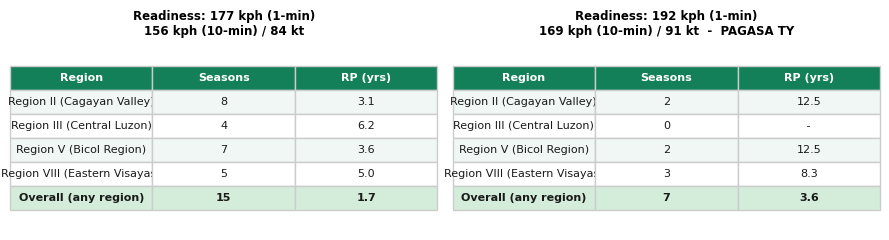

In [11]:
n_years = END_YEAR - START_YEAR + 1
all_years = list(range(START_YEAR, END_YEAR + 1))

# Second threshold to test
TEST_KPH_1MIN  = 192
TEST_KPH_10MIN = round(TEST_KPH_1MIN * 0.88)       # 169 kph
TEST_KT        = TEST_KPH_1MIN * 0.88 / 1.852       # ~91.3 kt

df_readiness_test, storm_region_map_test = count_storms_per_region(
    tracks_pts, TEST_KT, store_storm_ids=True, count_seasons=True
)

results_test   = build_triggered_storms(tracks_pts, TEST_KT, target_union)
triggered_test = results_test[results_test["triggered"]]

# Once-per-season rule for both thresholds
season_worst = (
    triggered.groupby("year")["trigger_wind_kt"].max()
    .reindex(all_years, fill_value=0).reset_index()
    .rename(columns={"trigger_wind_kt": "max_trigger_wind_kt"})
)
triggered_seasons      = season_worst[season_worst["max_trigger_wind_kt"] > 0].reset_index(drop=True)
n_triggered_seasons    = len(triggered_seasons)
n_triggered_seasons_test = triggered_test["year"].nunique()

def build_rp_df(df_region, n_seasons):
    rows = []
    for _, r in df_region.iterrows():
        count = r["Count"]
        rp = round(n_years / count, 1) if count > 0 else " - "
        rows.append({"Region": r["Region"], "Seasons": count, "RP (yrs)": rp})
    rows.append({
        "Region": "Overall (any region)",
        "Seasons": f"{n_seasons}",
        "RP (yrs)": round(n_years / n_seasons, 1) if n_seasons > 0 else " - ",
    })
    return pd.DataFrame(rows)

rp_df      = build_rp_df(df_readiness,      n_triggered_seasons)
rp_df_test = build_rp_df(df_readiness_test, n_triggered_seasons_test)

print(f"Record: {n_years} years ({START_YEAR}-{END_YEAR}) | Once-per-season rule\n")
for label, df in [
    (f"{THRESHOLD_KPH_1MIN} kph (1-min) / {round(THRESHOLD_KPH_10MIN)} kph (10-min)", rp_df),
    (f"{TEST_KPH_1MIN} kph (1-min) / {TEST_KPH_10MIN} kph (10-min)  -  PAGASA Typhoon", rp_df_test),
]:
    print(f"  {label}")
    print(df.to_string(index=False))
    print()

def render_rp_table(ax, df, title):
    ax.axis("off")
    ax.set_title(title, fontsize=8.5, fontweight="bold", pad=8)
    table = ax.table(
        cellText=df.values.tolist(),
        colLabels=list(df.columns),
        loc="center", cellLoc="center"
    )
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.5)
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if row == 0:
            cell.set_facecolor("#14805a")
            cell.set_text_props(color="white", fontweight="bold")
        elif row == len(df):
            cell.set_facecolor("#d4edda")
            cell.set_text_props(color="#1a1a1a", fontweight="bold")
        else:
            cell.set_facecolor(["#f0f7f4", "#ffffff"][(row - 1) % 2])
            cell.set_text_props(color="#1a1a1a")

fig, axes = plt.subplots(1, 2, figsize=(9, 2.5))
render_rp_table(
    axes[0], rp_df,
    f"Readiness: {THRESHOLD_KPH_1MIN} kph (1-min)\n{round(THRESHOLD_KPH_10MIN)} kph (10-min) / {THRESHOLD_KT:.0f} kt"
)
render_rp_table(
    axes[1], rp_df_test,
    f"Readiness: {TEST_KPH_1MIN} kph (1-min)\n{TEST_KPH_10MIN} kph (10-min) / {TEST_KT:.0f} kt  -  PAGASA TY"
)
plt.tight_layout()
plt.show()

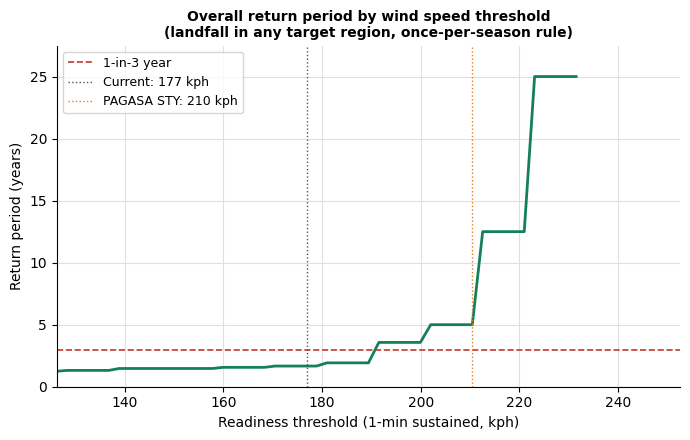

Current (177 kph 1-min): 15 seasons → RP 1.7 years
PAGASA STY (~210 kph 1-min): 5 seasons → RP 5.0 years

1-in-3 year RP: 192 kph (1-min) / 91 kt (10-min WMO)


In [12]:
# Pre-compute for each storm: the maximum min(w0,w1) across all segments that
# cross target_union. This is the highest threshold at which that storm would trigger.
storm_landfall = {}
for storm_id, grp in tracks_pts.sort_values("valid_time").groupby("storm_id"):
    grp = grp.reset_index(drop=True)
    year = grp["valid_time"].dt.year.iloc[0]
    best_wind = 0
    for i in range(len(grp) - 1):
        p0, p1 = grp.iloc[i], grp.iloc[i + 1]
        if pd.isna(p0["wind_speed"]) or pd.isna(p1["wind_speed"]):
            continue
        seg = LineString([(p0.geometry.x, p0.geometry.y), (p1.geometry.x, p1.geometry.y)])
        if seg.intersects(target_union):
            best_wind = max(best_wind, min(p0["wind_speed"], p1["wind_speed"]))
    if best_wind > 0:
        storm_landfall[storm_id] = {"wind_kt": best_wind, "year": year}

# Sweep thresholds and compute overall RP (once-per-season rule)
thresholds_kt = np.arange(60, 121, 1)
rp_curve = np.array([
    n_years / len({v["year"] for v in storm_landfall.values() if v["wind_kt"] >= T})
    if any(v["wind_kt"] >= T for v in storm_landfall.values()) else np.inf
    for T in thresholds_kt
])

# Convert kt (10-min) → kph (1-min) for x-axis labelling
thresholds_kph_1min = thresholds_kt * 1.852 / 0.88

CURRENT_KPH = THRESHOLD_KPH_1MIN        # 177 kph (1-min)
STY_KPH     = 100 * 1.852 / 0.88        # PAGASA STY: 100 kt 10-min → ~210 kph 1-min

fig, ax = plt.subplots(figsize=(7, 4.5))
finite_rp = rp_curve[np.isfinite(rp_curve)]
ax.plot(thresholds_kph_1min[np.isfinite(rp_curve)], finite_rp, color="#14805a", linewidth=2)

ax.axhline(3, color="#c0392b", linewidth=1.2, linestyle="--", label="1-in-3 year")
ax.axvline(CURRENT_KPH, color="#555", linewidth=1, linestyle=":", label=f"Current: {int(CURRENT_KPH)} kph")
ax.axvline(STY_KPH, color="#e67e22", linewidth=1, linestyle=":", label=f"PAGASA STY: {STY_KPH:.0f} kph")

ax.set_xlabel("Readiness threshold (1-min sustained, kph)", fontsize=10)
ax.set_ylabel("Return period (years)", fontsize=10)
ax.set_title(
    "Overall return period by wind speed threshold\n(landfall in any target region, once-per-season rule)",
    fontsize=10, fontweight="bold"
)
ax.set_ylim(0, min(finite_rp.max() * 1.1, 40))
ax.set_xlim(thresholds_kph_1min[0], thresholds_kph_1min[-1])
ax.legend(fontsize=9)
ax.xaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# RP at key thresholds
for label, kph in [("Current (177 kph 1-min)", CURRENT_KPH), ("PAGASA STY (~210 kph 1-min)", STY_KPH)]:
    kt = kph * 0.88 / 1.852
    seasons = {v["year"] for v in storm_landfall.values() if v["wind_kt"] >= kt}
    rp = round(n_years / len(seasons), 1) if seasons else " - "
    print(f"{label}: {len(seasons)} seasons → RP {rp} years")

# Threshold that achieves 1-in-3 year RP
idx_3yr = np.where(rp_curve >= 3)[0]
if len(idx_3yr) > 0:
    kph_3yr = thresholds_kph_1min[idx_3yr[0]]
    kt_3yr  = thresholds_kt[idx_3yr[0]]
    print(f"\n1-in-3 year RP: {kph_3yr:.0f} kph (1-min) / {kt_3yr:.0f} kt (10-min WMO)")

## Readiness activation by season (2000-2024)

In [13]:
triggered_177_years = set(triggered["year"].astype(int).tolist())
triggered_192_years = set(triggered_test["year"].astype(int).tolist())

region_short = {
    "Region II (Cagayan Valley)":    "Region 2",
    "Region III (Central Luzon)":    "Region 3",
    "Region V (Bicol Region)":       "Region 5",
    "Region VIII (Eastern Visayas)": "Region 8",
}

def build_year_details(triggered_df, srmap):
    details = {}
    for _, row in triggered_df.sort_values("year").iterrows():
        year = int(row["year"])
        regions = [region_short.get(r, r) for r in srmap.get(row["storm_id"], [])]
        entry = f"{row['name']} ({', '.join(regions)})" if regions else row["name"]
        details.setdefault(year, []).append(entry)
    return details

details_177 = build_year_details(triggered,      storm_region_map)
details_192 = build_year_details(triggered_test, storm_region_map_test)

rows = []
for year in range(START_YEAR, END_YEAR + 1):
    r177 = "" + "  ·  ".join(details_177.get(year, [])) if year in triggered_177_years else " - "
    r192 = "" + "  ·  ".join(details_192.get(year, [])) if year in triggered_192_years else " - "
    rows.append({
        "Year": year,
        f"177 kph (1-min) / {round(THRESHOLD_KPH_10MIN)} kph (10-min)": r177,
        f"192 kph (1-min) / {TEST_KPH_10MIN} kph (10-min)": r192,
    })

df_timeline = pd.DataFrame(rows).set_index("Year")

with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(df_timeline)

,177 kph (1-min) / 156 kph (10-min),192 kph (1-min) / 169 kph (10-min)
Year,,
2000,-,-
2001,-,-
2002,-,-
2003,-,-
2004,Nida (Region 5),-
2005,-,-
2006,Durian (Region 5) · Cimaron (Region 2) · Chebi (Region 3),-
2007,-,-
2008,-,-
